# Sequence algorithms for genome assembly and read analysis

Python implementations and worked solutions: suffix-prefix overlap, directed graphs, overlap and de Bruijn graphs, the Burrows-Wheeler transform, FASTQ/Phred encoding and a hidden Markov model.


## Exercise 1

In Python, define a function overlap that takes two strings, say x and y, and returns their largest suffix-prefix overlap where the suffix must come from x and the prefix must come from y. Test your function using overlap(“GTACC”, “CCATG”). Extend it to return also the corresponding overlap length in a format of your choice. Research the term suffix array, and calculate it for “GTACC”, by hand.

In [1]:
def overlap(x, y):
    """Return (overlap_string, overlap_length): largest suffix of x = prefix of y."""
    best = ("", 0)
    for k in range(1, min(len(x), len(y)) + 1):
        if x[-k:] == y[:k]:
            best = (x[-k:], k)
    return best

print(overlap("GTACC", "CCATG"))  # ('CC', 2)

('CC', 2)


overlap("GTACC", "CCATG") → ('CC', 2)  [overlap length = 2]


### Exercise 1 Part 2 Suffix Array — by hand for "GTACC"

i   Suffix

0	GTACC

1	TACC

2	ACC

3	CC

4	C

```

SA("GTACC") = [2, 4, 3, 0, 1]


Sorted lexicographically: ACC(2), C(4), CC(3), GTACC(0), TACC(1)


## Exercise 2

In Python, define a class DiGraph that implements a directed graph. The class must represent nodes, edges and edge labels. Test the class using following assignments:
a = DiGraph()
b = DiGraph(nodes=[1,2], edges=[(1,2)])
c = DiGraph(nodes=[1], edges=[(1,1)], edge_labels=[2])
Add a method to DiGraph, that checks whether there is a directed path between nodes i and j.

In [2]:
class DiGraph:
    def __init__(self, nodes=None, edges=None, edge_labels=None):
        self.nodes = set(nodes) if nodes else set()
        self.edges = list(edges) if edges else []
        self.edge_labels = list(edge_labels) if edge_labels else []
        for (u, v) in self.edges:
            self.nodes.add(u); self.nodes.add(v)

    def has_path(self, i, j):
        """BFS: directed path from i to j."""
        if i not in self.nodes or j not in self.nodes:
            return False
        adj = {n: [] for n in self.nodes}
        for (u, v) in self.edges:
            adj[u].append(v)
        visited, queue = set(), [i]
        while queue:
            node = queue.pop(0)
            if node == j: return True
            if node in visited: continue
            visited.add(node)
            queue.extend(adj[node])
        return False

a = DiGraph()
b = DiGraph(nodes=[1,2], edges=[(1,2)])
c = DiGraph(nodes=[1], edges=[(1,1)], edge_labels=[2])

b.has_path(1, 2) → True

b.has_path(2, 1) → False

c.has_path(1, 1) → True  (self-loop)

##  Exercise 3 Overlap Graph (by hand) — Hamiltonian paths

By hand, draw an overlap graph for GTGCA, CGTGC, CGAC, CGAC, and CAGC, and if possible, write out all Hamiltonian paths. Suggest an assembly.

Reads: GTGCA, CGTGC, CGAC, CGAC, CAGC

Overlaps (suffix of row → prefix of col, min k=1, only meaningful ≥2 shown):


In [3]:
import pandas as pd

labels = ["GTGCA", "CGTGC", "CGAC", "CGAC", "CAGC"]
data = [
    ["—", "", "", "", ""],
    ["GTGC→GTGCA (4)", "—", "", "", ""],
    ["", "", "—", "CGAC (4)", "C→CAGC (1)"],
    ["", "", "CGAC (4)", "—", "C→CAGC (1)"],
    ["", "C→CGTGC (1)", "C→CGAC (1)", "C→CGAC (1)", "—"],
]

df = pd.DataFrame(data, index=labels, columns=labels)
df.style.set_caption("Overlap Graph — suffix→prefix overlaps")

,GTGCA,CGTGC,CGAC,CGAC,CAGC
GTGCA,—,,,,
CGTGC,GTGC→GTGCA (4),—,,,
CGAC,,,—,CGAC (4),C→CAGC (1)
CGAC,,,CGAC (4),—,C→CAGC (1)
CAGC,,C→CGTGC (1),C→CGAC (1),C→CGAC (1),—


  CGTGC ──(4)──> GTGCA

  ^

  │(1)
  
  CAGC ──(1)──> CGAC ──(4)──> CGAC

Hamiltonian path (visiting all 5 nodes once):
CGTGC → GTGCA and CGAC → CGAC → CAGC → CGTGC gives a cycle if we allow length-1 overlaps.
One Hamiltonian path: CAGC → CGAC → CGAC → CGTGC → GTGCA
(CAGC→CGAC via C, CGAC→CGAC via CGAC, CGAC→CGTGC via C, CGTGC→GTGCA via GTGC)

Assembly: CAGCGACGTGCA

## Exercise 4 de Bruijn Graph (k=3) — Eulerian paths

By hand, drawn a de Bruijn graph using a k=3, where k gives the k-mer size, for the same strings as in exercise 3. Assess existence of an Eulerian path, and if possible, write out all Eulerian paths. Suggest an assembly.

Reads: GTGCA, CGTGC, CGAC, CGAC, CAGC
k-mers (k=3) from all reads → edges are 2-mers, nodes are (k-1)-mers = 2-mers:


GTGCA: GTG, TGC, GCA

CGTGC: CGT, GTG, TGC

CGAC:  CGA, GAC  (×2, from both copies)

CAGC:  CAG, AGC

Each k-mer (a,b,c) gives edge: node ab → bc

Edges (node → node, label = k-mer):

GT→TG (GTG), TG→GC (TGC), GC→CA (GCA)

CG→GT (CGT), GT→TG (GTG), TG→GC (TGC)

CG→GA (CGA) ×2, GA→AC (GAC) ×2

CA→AG (CAG), AG→GC (AGC)


Node in-degrees / out-degrees:

GT: in=1(CG→GT), out=2(GT→TG×2) — out > in by 1 → Eulerian start candidate

GC: in=2(TG→GC×2)+1(AG→GC), out=1(GC→CA) — in > out by 2

TG: in=2, out=2 ✓

CA: in=1, out=1 ✓

CG: in=0, out=3 — out > in by 3

GA: in=2, out=2 ✓

AC: in=2, out=0

AG: in=1, out=1 ✓

Eulerian path condition: Exactly 0 or 2 nodes with unequal in/out degree.
Here CG (out−in=3), GT (out−in=1), GC (in−out=2), AC (in−out=2) are unbalanced → no single Eulerian path exists over all edges simultaneously.

 restrict to one copy of each unique k-mer:
Unique k-mers: GTG, TGC, GCA, CGT, CGA, GAC, CAG, AGC (8 edges)

Suggested assembly from de Bruijn paths:
Path 1: CG → GT → TG → GC → CA → AG → GC → CA (partial)
Likely assembled contig: CGTGCA + CGAC → CGACGTGCA or CAGCGACGTGCA

## Exercise 5 Motif Likelihood & Posterior — Sliding Window
Suppose I tell you that there is a specific DNA motif of length k=4, denoted (a, b, c, d), where the letters represent the base states at the four positions, e.g., GTAT, which is characterized by the following likelihood, Pr[(a, b, c, d) | motif] = P[a] P[b] P[c] Q[d], where for a given base x, P[x] = ½ when x=”T” and 1/6 otherwise, and Q[x] = 0 when x=”A”, and 1/3 otherwise.
(a) With Python, use a sliding window approach to determine Pr[(a, b, c, d) | motif] across the sequence provided below for every window. Visualize this profile in a pretty figure (using matplotlib).


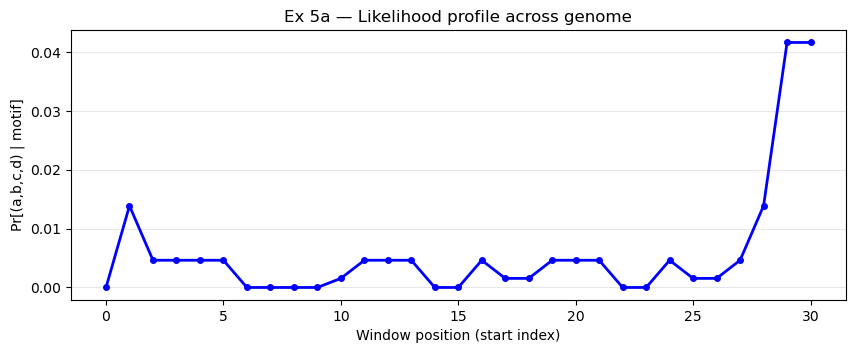

In [16]:
genome = "TTTAGTCGTAAAATCGTAACGTCGTAACGTTTTT"
k = 4

def P(x): return 0.5 if x == 'T' else 1/6
def Q(x): return 0.0 if x == 'A' else 1/3
def pr_motif_given_seq(w): return P(w[0]) * P(w[1]) * P(w[2]) * Q(w[3])

windows = [genome[i:i+k] for i in range(len(genome)-k+1)]
likelihoods = [pr_motif_given_seq(w) for w in windows]
positions = list(range(len(windows)))

# Figure 5a
plt.figure(figsize=(10, 3.5))
plt.plot(positions, likelihoods, color='blue', lw=2, marker='o', ms=4)
plt.xlabel('Window position (start index)')
plt.ylabel('Pr[(a,b,c,d) | motif]')
plt.title('Ex 5a — Likelihood profile across genome')
plt.grid(axis='y', alpha=0.3)
plt.show()


### Exercise 5b

(b) With Python, determine Pr[motif | (a, b, c, d)] in the same manner as in (a) using a sliding window. Also visualize this profile in a pretty figure (using matplotlib). By hand, show how Pr[motif | (a, b, c, d)] can be determined.

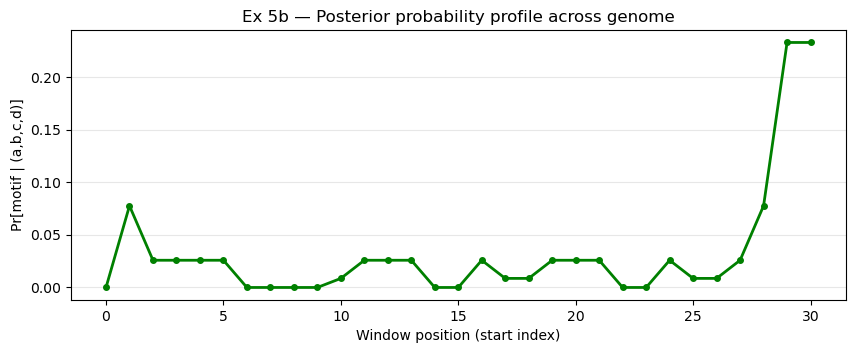

In [14]:
N = len(windows)
prior_motif = 1.0 / N
pr_seq = sum(likelihoods) * prior_motif
posteriors = [l * prior_motif / pr_seq for l in likelihoods]

plt.figure(figsize=(10, 3.5))
plt.plot(positions, posteriors, color='green', lw=2, marker='o', ms=4)
plt.xlabel('Window position (start index)')
plt.ylabel('Pr[motif | (a,b,c,d)]')
plt.title('Ex 5b — Posterior probability profile across genome')
plt.grid(axis='y', alpha=0.3)
plt.show()

### Exercise 5c

In at most three sentences, describe the motif (regarding position specificity and dependence among positions), and conclude on your findings derived from the sliding-window profiles. Describe the base composition of the fantasy genome below.
For your analysis assume that the entire genome (of some fantasy species) under analysis is given by this one string: TTTAGTCGTAAAATCGTAACGTCGTAACGTTTTT

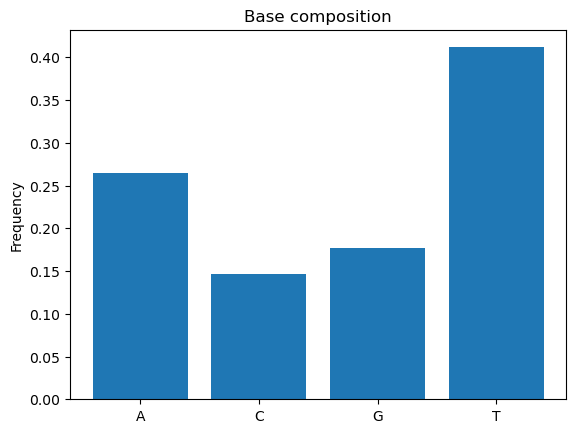

In [22]:
import matplotlib.pyplot as plt

genome = "TTTAGTCGTAAAATCGTAACGTCGTAACGTTTTT"
bases = ['A', 'C', 'G', 'T']
freqs = [genome.count(b) / len(genome) for b in bases]

plt.bar(bases, freqs)
plt.title('Base composition')
plt.ylabel('Frequency')
plt.show()

## Exercise 6 FASTQ file & Phred scores
Suppose, I hand you a read “AGTCGTAACGT” named “read 1001 of experiment 421”, which has been derived from a sequencer that does not do mistakes at any position but the last. At the last position it introduces a miscalled base with probability 0.01. I ask you to store this information in a FASTQ file. Develop the file’s contents. Then, by hand, show how you would calculate the Phred score for a base that is correct with probability 0.00023. By hand, determine the probability that a base is wrong when the Pred score is encoded with a “>”. Use online research for help. Clearly, the Phred score (a number) to character mapping is not something one has to remember.

Read: AGTCGTAACGT, name: read 1001 of experiment 421. All bases correct except last (error prob = 0.01).

#### Phred score formula
Q = −10 · log₁₀(p_error)  →   ASCII char = chr(Q + 33)

For p=0: Q = ∞ → capped at Q=40 (Illumina max) → char I (ASCII 73)
For p=0.01: Q = −10·log₁₀(0.01) = 20 → char 5 (ASCII 53)


### FASTQ file

@read 1001 of experiment 421
AGTCGTAACGT
+
IIIIIIIIIII5


#### By hand — Phred for p = 0.00023:

Q = −10 · log₁₀(0.00023)

log₁₀(0.00023) = log₁₀(2.3 × 10⁻⁴) = log₁₀(2.3) + (−4) ≈ 0.362 − 4 = −3.638

Q = −10 × (−3.638) = 36.38 ≈ 36

ASCII: 36 + 33 = 69 → chr(69) = 'E'

#### By hand — p_wrong for Phred '>':

ASCII('>') = 62 → Q = 62 − 33 = 29

p_error = 10^(−Q/10) = 10^(−2.9) ≈ 0.00126

## Exercise 7
Suppose, I hand you another read “TGTTTA” derived from the same sequencing experiment, called “read 1002 of experiment 421”. Add it to the FASTQ file from exercise 6, and present the contents. Generate the contents of a corresponding FASTA file. Determine the structure of a FASTA file using online research

FASTQ structure (4 lines per read):
Line 1: @identifier   Line 2: sequence   Line 3: +   Line 4: quality string (same length as seq)


@read 1001 of experiment 421

AGTCGTAACGT
+
IIIIIIIIII5

@read 1002 of experiment 421

TGTTTA
+
IIIII5

Corresponding FASTA file

read 1001 of experiment 421 (identifier line)

AGTCGTAACGT (sequence)

read 1002 of experiment 421 (identifier line)

TGTTTA AGTCGTAACGT (sequence)


## Exercise 8 

By hand, find the Burrows-Wheeler transform BWT(T) of T=“ATGCATTA”. By hand, use the inverse transform to find T from BWT(T).

0:  A T G C A T T A $

1:  T G C A T T A $ A

2:  G C A T T A $ A T

3:  C A T T A $ A T G

4:  A T T A $ A T G C

5:  T T A $ A T G C A

6:  T A $ A T G C A T

7:  A $ A T G C A T T

8:  $ A T G C A T T A

#### sort lexicographically

$ATGCATTA    → last char: A

A$ATGCATT    → last char: T

ATGCATTA$    → last char: $

ATTA$ATGC    → last char: C

CATTA$ATG    → last char: G

GCATTA$AT    → last char: T

TA$ATGCAT    → last char: T

TGCATTA$A    → last char: A

TTA$ATGCA    → last char: A

BWT("ATGCATTA") = AT$CGTTAA





### inverse BWT

L = A T $ C G T T A A

F = $ A A A C G T T T   (L sorted)

L (BWT) and F (BWT sorted) side by side, number repeated chars:
Row   F     L

 0    $     A₁

 1    A₁    T₁

 2    A₂    $

 3    A₃    C

 4    C     G

 5    G     T₂

 6    T₁    T₃

 7    T₂    A₂
 
 8    T₃    A₃

------------------------------------------------------------------------------------------------------------------------------------------

A₁ in L (row 0) → A₁ in F (row 1)

T₁ in L (row 1) → T₁ in F (row 6)

$  in L (row 2) → $  in F (row 0)

C  in L (row 3) → C  in F (row 4)

G  in L (row 4) → G  in F (row 5)

T₂ in L (row 5) → T₂ in F (row 7)

T₃ in L (row 6) → T₃ in F (row 8)

A₂ in L (row 7) → A₂ in F (row 2)

A₃ in L (row 8) → A₃ in F (row 3)

------------------------------------------------------------------------------------------------------------------------------------------


Row 0:  F=$   L=A₁  → string: A$          → jump to row 1

Row 1:  F=A₁  L=T₁  → string: TA$         → jump to row 6

Row 6:  F=T₁  L=T₃  → string: TTA$        → jump to row 8

Row 8:  F=T₃  L=A₃  → string: ATTA$       → jump to row 3

Row 3:  F=A₃  L=C   → string: CATTA$      → jump to row 4

Row 4:  F=C   L=G   → string: GCATTA$     → jump to row 5

Row 5:  F=G   L=T₂  → string: TGCATTA$    → jump to row 7

Row 7:  F=T₂  L=A₂  → string: ATGCATTA$   → jump to row 2

Row 2:  F=A₂  L=$   → stop


------------------------------------------------------------------------------------------------------------------------------------------

ATGCATTA$

Drop the sentinel $:

T = ATGCATTA

## Exercise 9
In Python, define a function BWT that determines the Burrows-Wheeler transform for a provided string.

In [24]:
def BWT(T):
    T = T + '$'
    n = len(T)
    rotations = [T[i:] + T[:i] for i in range(n)]
    return ''.join(r[-1] for r in sorted(rotations))

BWT("CATGATATGATATGATTTATGATC")

'CGGGCTTTGT$TTTTATAAAAAATA'

## Exercise 10
In Python, define a function IBWT that determines the inverse Burrows-Wheeler transform for a provided string. Run BWT(“CATGATATGATATGATTTATGATC”), and then IBWT on the returned result.

In [25]:
#BWT

def BWT(T):
    T = T + '$'
    n = len(T)
    rotations = [T[i:] + T[:i] for i in range(n)]
    return ''.join(r[-1] for r in sorted(rotations))

BWT("CATGATATGATATGATTTATGATC")

'CGGGCTTTGT$TTTTATAAAAAATA'

In [26]:
#IBWT

def IBWT(bwt):
    n = len(bwt)
    table = [''] * n
    for _ in range(n):
        table = sorted([bwt[i] + table[i] for i in range(n)])
    return next(s[:-1] for s in table if s.endswith('$'))

bwt_result = BWT("CATGATATGATATGATTTATGATC")
IBWT(bwt_result)

'CATGATATGATATGATTTATGATC'

## Exercise 11
Define a function give_starting_position that returns all starting positions of string x within string y. If x is not a substring of y, the function should return an empty list. Use the Burrows-Wheeler approach presented in class, from first principles.

In [29]:
def give_starting_positions(x, y):
    return [i for i in range(len(y)) if y[i:i+len(x)] == x]

print(give_starting_positions('CGT', 'TTTAGTCGTAAAATCGTAACGT'))

[6, 14, 19]


## Exercise 12
Choose one short-read and one long-read sequencing technology. Find out which type of data (the raw signal) is fed to the “base caller” for that technology, and describe it. Does this technology multiplex (read multiple reads at once, or just one read at any point in time)? In both cases, suggest in words a machine learning approach that can be applied to target this specific base-calling problem – focus on input and output data, not so much on the actual model family. Be concise.

##### Short-read: Illumina
The raw signal is fluorescence images — each incorporated base emits a different color, captured by a camera every cycle.
It is multiplexed — millions of clusters are sequenced in parallel on the same flow cell.
ML approach: input is a series of color intensity values per cluster per cycle, output is a base + quality score. A CNN or LSTM can learn this mapping.

##### long-read: Oxford Nanopore (ONT)
The raw signal is an electric current trace — as DNA passes through a tiny pore, the current changes depending on which bases are inside it.
It is multiplexed — thousands of pores run simultaneously, each reading one molecule at a time.
ML approach: input is a time-series of current values, output is a base sequence. A recurrent network (like an LSTM) with a CTC decoder is typically used to map the variable-length signal to bases.

## Exercise 13

By hand, draw a plot, that displays how you think the Phred score behaves, on average, across reads from the 5’ to the 3’ end. In one sentence address: Which phenomena during sequencing explain your suggested picture?

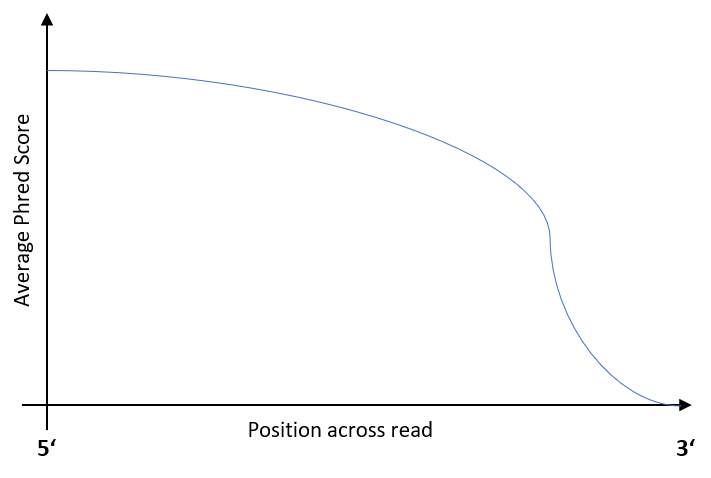

In [5]:
from IPython.display import Image, display

display(Image(filename='Picture1.png'))



Phred quality starts high near the 5′ end and gradually declines toward the 3′ end. This is explained by signal decay and dye bleaching in sequencing-by-synthesis: as cycles progress, fluorescent signals weaken, more clusters fall out of phase (phasing/pre-phasing), and incorporated dye molecules accumulate photo-damage, making base calls increasingly uncertain at later positions.

## Exercise 14

Let us consider a hidden Markov model (HMM) with hidden states H and T. By hand, determine the likelihood of the following sequence of hidden states HTHHT given the data ATGCA. The transition matrix for the hidden states, A, and the emission probabilities, B, are provided below. In Python, define a function that does this calculation for you for arbitrary a list of states, a list of emissions, and arbitrary, A and B that suit. Is the hidden state sequence HHHHH more likely?

In [6]:
def hmm_likelihood(states, emissions, A, B, pi):
    p = pi[states[0]] * B[states[0]][emissions[0]]
    for t in range(1, len(states)):
        p *= A[states[t-1]][states[t]] * B[states[t]][emissions[t]]
    return p

A = {'H': {'H': 0.9, 'T': 0.1},
     'T': {'H': 0.1, 'T': 0.9}}

B = {'H': {'A': 0.2, 'T': 0.2, 'G': 0.3, 'C': 0.3},
     'T': {'A': 0.3, 'T': 0.3, 'G': 0.2, 'C': 0.2}}

pi = {'H': 0.5, 'T': 0.5}

p1 = hmm_likelihood(['H','T','H','H','T'], ['A','T','G','C','A'], A, B, pi)
p2 = hmm_likelihood(['H','H','H','H','H'], ['A','T','G','C','A'], A, B, pi)

print(p1)
print(p2)
print('HHHHH more likely:', p2 > p1)

7.29e-07
0.0002361960000000001
HHHHH more likely: True


HHHHH is more likely — it avoids the costly H→T and T→H transitions (each 0.1 vs 0.9) and G/C are emitted with higher probability from H than T.